In [2]:
!git log --oneline

6290fc4 (HEAD -> main) Add notebook: enviroment setup and version check
eeb2c6c Install commit


# MOP 3231 · Week 2 Lab / Task 1
## Data Preprocessing & Cleaning

Student: Nuray Aben
ID: 2653
Date: 27.09.2026

In [4]:
import sys
import numpy as np
import pandas as pd
import matplotlib
import sklearn

print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__)
print("pandas:", pd.__version__)
print("matplotlib:", matplotlib.__version__)
print("scikit-learn:", sklearn.__version__)

Python: 3.12.7
NumPy: 2.0.2
pandas: 2.3.3
matplotlib: 3.9.4
scikit-learn: 1.6.1


In [9]:
raw = pd.read_csv("data/almaty_apartments_raw.csv")
YOUR_ID = 2653
ids = raw["listing_id"].drop_duplicates().sample(frac=0.9, random_state=YOUR_ID)
df = raw[raw["listing_id"].isin(ids)].reset_index(drop=True)
print("raw.shape:", raw.shape)
print("df.shape:", df.shape)
print("уникальных listing_id в raw:", raw["listing_id"].nunique())
print("уникальных listing_id в df:", df["listing_id"].nunique())
print("exact duplicates:", df.duplicated().sum())
print("reposts:", df.drop_duplicates()["listing_id"].duplicated().sum())

raw.shape: (1284, 11)
df.shape: (1160, 11)
уникальных listing_id в raw: 1200
уникальных listing_id в df: 1080
exact duplicates: 35
reposts: 45


raw это у нас весь исходной файл там у нас 1284 строк и 11 колонок
df рабочая таюлица после которого я взяла случайные 90%, 1169 строк и 11 колонок
в исходном файле уникальных listing_id 1200 разных объвлений получается остальные 84 повторные обьявления
в рабочем датасете уникальных id 1080 остальные 80 повторы
пропорция та же 1080/1200=0.9=90%


In [10]:
before = len(df)

df = df.drop_duplicates().reset_index(drop=True)

df["listed_date"] = pd.to_datetime(df["listed_date"])
df = df.sort_values("listed_date").drop_duplicates("listing_id", keep="last").reset_index(drop=True)

after = len(df)
print("before:", before, "after:", after, "removed:", before - after)
print("уникальных listing_id:", df["listing_id"].nunique())

before: 1160 after: 1080 removed: 80
уникальных listing_id: 1080


удаляем дубликаты так как уникальные значения они не должны повторятся

In [11]:
print(df["district"].value_counts())

district
Medeu            132
Bostandyk        125
Turksib          120
Auezov           116
Zhetysu          114
Almaly           109
Alatau           107
Nauryzbay        100
medeu              9
turksib            9
auezov             7
 Auezov            7
 Zhetysu           6
bostandyk          6
Nauryzbayskiy      6
Alatauskiy         6
Наурызбайский      6
Auezovskiy         6
AUEZOV             6
BOSTANDYK          5
nauryzbay          5
Bostandykskiy      5
Медеуский          4
ZHETYSU            4
 Medeu             4
 Alatau            4
TURKSIB            4
almaly             4
ALMALY             4
Zhetysuskiy        3
Бостандыкский      3
Турксибский        3
 Turksib           3
 Almaly            3
Almalinskiy        3
NAURYZBAY          3
 Bostandyk         3
MEDEU              3
ALATAU             3
Turksibskiy        2
Ауэзовский         2
Medeuskiy          1
Алмалинский        1
zhetysu            1
 Nauryzbay         1
alatau             1
Жетысуский         1
Name

в датасете один и тот же район записан по разному: 8 правильных названий :(Medeu, Bostandyk, Turksib, Auezov, Zhetysu, Almaly, Alatau, Nauryzbay — у них большие числа) и ещё много кривых вариантов тех же районов с маленькой буквы 

In [12]:
df["district"] = df["district"].str.strip().str.casefold()

mapping = {
    "alatau": "Alatau", "alatauskiy": "Alatau", "алатауский": "Alatau",
    "almaly": "Almaly", "almalinskiy": "Almaly", "алмалинский": "Almaly",
    "auezov": "Auezov", "auezovskiy": "Auezov", "ауэзовский": "Auezov",
    "bostandyk": "Bostandyk", "bostandykskiy": "Bostandyk", "бостандыкский": "Bostandyk",
    "medeu": "Medeu", "medeuskiy": "Medeu", "медеуский": "Medeu",
    "nauryzbay": "Nauryzbay", "nauryzbayskiy": "Nauryzbay", "наурызбайский": "Nauryzbay",
    "turksib": "Turksib", "turksibskiy": "Turksib", "турксибский": "Turksib",
    "zhetysu": "Zhetysu", "zhetysuskiy": "Zhetysu", "жетысуский": "Zhetysu",
}

df["district"] = df["district"].map(mapping)

print("nunique:", df["district"].nunique())
print("NaN:", df["district"].isna().sum())
print(df["district"].value_counts())

nunique: 8
NaN: 0
district
Medeu        153
Bostandyk    147
Auezov       144
Turksib      141
Zhetysu      129
Almaly       124
Alatau       121
Nauryzbay    121
Name: count, dtype: int64


тут привели все варианты написания районов к единому виду. Убрали пробелы, а mapping заменил 24 разных варианта на 8 канонических названий (Alatau, Almaly, Auezov, Bostandyk, Medeu, Nauryzbay, Turksib, Zhetysu). 

In [13]:
for col in ["rooms", "area_m2", "price_kzt"]:
    print("===", col, "===")
    print(df[col].dropna().sample(10, random_state=YOUR_ID).tolist())

=== rooms ===
['3', '2', '5', 'studio', '3', '2', '3', '2', '2', '3']
=== area_m2 ===
['73.1', '61.1 m²', '156.6', '32.4', '78.1', '55.5', '84.4 m²', '52.7', '53.7', '75.6']
=== price_kzt ===
['36070000', '62 020 000 ₸', '162880000', '23030000', '84310000', '62610000', '82 080 000 ₸', '56000000', '38290000', '49100000']


тут видим что rooms сщдержит текст вместе с числами, а в area_m2 нескольо значений с суфиксом м^2 в price_kzt есть числа с пробелами

In [14]:
df["rooms"] = df["rooms"].replace("studio", 1)
df["rooms"] = pd.to_numeric(df["rooms"], errors="coerce")
print("rooms NaN:", df["rooms"].isna().sum())


rooms NaN: 0


заменили студио на число, а потом через pd.to_numeric превратили всю колонку в числа. Результат NaN: 0 означает, что все значения стали числовыми — задача по rooms выполнена.

In [15]:
df["area_m2"] = (
    df["area_m2"].astype(str)
      .str.replace("m²", "", regex=False)
      .str.strip()
      .str.replace(",", ".", regex=False)
)
df["area_m2"] = pd.to_numeric(df["area_m2"], errors="coerce")
print("area_m2 NaN:", df["area_m2"].isna().sum())

area_m2 NaN: 0


In [16]:
df["price_kzt"] = (
    df["price_kzt"].astype(str)
      .str.replace(r"\D", "", regex=True)
)
df["price_kzt"] = pd.to_numeric(df["price_kzt"], errors="coerce")
print("price_kzt NaN:", df["price_kzt"].isna().sum())

price_kzt NaN: 0


In [17]:
print(df[["rooms", "area_m2", "price_kzt"]].dtypes)
print(df["district"].nunique())
print("shape:", df.shape)

rooms          int64
area_m2      float64
price_kzt      int64
dtype: object
8
shape: (1080, 11)


Все три колонки приведены к числам. В area_m2 убрали суффикс, пробелы и заменили запятую на точку, потом через to_numeric превратили в float. В price_kzt удалили всё, кроме цифр (запятые, пробелы, символ тенге), и тоже превратили в число. 

Итог : 8 районов, все числа распарсены, shape = 1080 × 11.

In [18]:
print(df[["rooms", "floor", "total_floors", "year_built", "ceiling_height_m", "area_m2", "price_kzt"]].describe().T)

                   count          mean           std         min          25%  \
rooms             1080.0  2.257407e+00  1.002518e+00         1.0         1.75   
floor             1080.0  6.010185e+00  4.777621e+00        -1.0         3.00   
total_floors      1080.0  1.055556e+01  6.116620e+00         3.0         5.00   
year_built        1028.0  1.949595e+03  2.823900e+02         0.0      1972.00   
ceiling_height_m   955.0  2.708513e+00  4.581257e-01         0.0         2.62   
area_m2           1080.0  6.878778e+01  5.894366e+01        25.3        45.20   
price_kzt         1080.0  4.617664e+07  2.506332e+07  11440000.0  28082500.00   

                          50%          75%          max  
rooms                    2.00         3.00          5.0  
floor                    5.00         9.00         30.0  
total_floors             9.00        12.00         25.0  
year_built            1986.00      2010.00       2024.0  
ceiling_height_m         2.77         2.90          3.2  
are

отсюда мы видим что есть floor -1 - сентинел такого этажа не бывает
так же видим 0 в year_built так же сентинел года 0 тоже не бывает
ceiling_height_m есть 0 так же сентинел
три колонки с сентинелами

In [19]:
import numpy as np

for col, sentinel in [("year_built", 0), ("floor", -1), ("ceiling_height_m", 0)]:
    n = (df[col] == sentinel).sum()
    df[col] = df[col].replace(sentinel, np.nan)
    print(col, "sentinel replaced:", n)

print(df[["year_built", "floor", "ceiling_height_m"]].isna().sum())

year_built sentinel replaced: 21
floor sentinel replaced: 9
ceiling_height_m sentinel replaced: 23
year_built           73
floor                 9
ceiling_height_m    148
dtype: int64


Заменяем их на NaN

In [20]:
print("floor > total_floors:", (df["floor"] > df["total_floors"]).sum())
print("area_m2 > 300:", (df["area_m2"] > 300).sum())
print("year_built > 2026:", (df["year_built"] > 2026).sum())
print("rooms > 6:", (df["rooms"] > 6).sum())

print(df[df["area_m2"] > 300][["listing_id", "area_m2", "rooms", "price_kzt"]])

floor > total_floors: 12
area_m2 > 300: 11
year_built > 2026: 0
rooms > 6: 0
     listing_id  area_m2  rooms  price_kzt
3     ALM-10910    736.0      3   54050000
154   ALM-10276    604.0      2   33630000
171   ALM-10405    356.0      1   18830000
247   ALM-10072    530.0      2   64270000
318   ALM-10058    555.0      2   66270000
501   ALM-10921    668.0      3   38560000
651   ALM-10264    495.0      1   42680000
752   ALM-10909    565.0      2   32610000
938   ALM-10440    879.0      3   48370000
990   ALM-10069    481.0      2   27710000
1045  ALM-10659    544.0      2   25030000


loor > total_floors: 12 строк — этаж выше самого здания. Невозможно. 

area_m2 > 300: 11 строк — площадь 356, 495, 530, 555, 604, 668, 736, 879 м². Это не квартира — либо лишняя цифра, либо дом. Реальные квартиры в Алматы не бывают 600+ м². 

In [21]:
n1 = (df["floor"] > df["total_floors"]).sum()
df.loc[df["floor"] > df["total_floors"], "floor"] = np.nan

n2 = (df["area_m2"] > 300).sum()
df.loc[df["area_m2"] > 300, "area_m2"] = np.nan

print("floor > total_floors → NaN:", n1)
print("area_m2 > 300 → NaN:", n2)
print("NaN now:")
print(df[["floor", "area_m2"]].isna().sum())

floor > total_floors → NaN: 12
area_m2 > 300 → NaN: 11
NaN now:
floor      21
area_m2    11
dtype: int64


floor выше здания — не знаем, что неверно, поэтому обнуляем floor так безопаснее
невозможная площадь так же NaN
floor: было 9 NaN после сентинелов + 12 невозможных = 21 NaN. Совпадает.
area_m2: было 0 NaN + 11 невозможных = 11 NaN. Совпадает.


In [23]:
df["price_per_m2"] = df["price_kzt"] / df["area_m2"]
df["area_before_fix"] = df["area_m2"]


q1 = df["price_per_m2"].quantile(0.25)
q3 = df["price_per_m2"].quantile(0.75)
iqr = q3 - q1
low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr

print("Q1:", q1, "Q3:", q3, "IQR:", iqr)
print("fences:", low, high)
print("outside:", ((df["price_per_m2"] < low) | (df["price_per_m2"] > high)).sum())

Q1: 520246.4788732395 Q3: 914604.4624746451 IQR: 394357.98360140563
fences: -71290.49652886891 1506141.4378767535
outside: 0


outside = 0   потому что разброс цен за м² слишком большой Q1 = 520 246, Q3 = 914 604, IQR = 394 358
границы широкие  от -71 290 до 1 506 141 ₸/м².

In [24]:
def fences(values, groups=None):
    grouped = values if groups is None else values.groupby(groups)
    q1, q3 = grouped.quantile(0.25), grouped.quantile(0.75)
    if groups is not None:
        q1, q3 = groups.map(q1), groups.map(q3)
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

low_g, high_g = fences(df["price_per_m2"], df["district"])

mask_out = (df["price_per_m2"] < low_g) | (df["price_per_m2"] > high_g)
print("outside by district group:", mask_out.sum())

print(df[mask_out][["listing_id", "district", "area_m2", "rooms", "price_kzt", "price_per_m2"]])

outside by district group: 1
    listing_id   district  area_m2  rooms  price_kzt   price_per_m2
824  ALM-10605  Nauryzbay     54.3      2   36960000  680662.983425


Решение — считать fences по каждому district отдельно. В разных районах Алматы цены разные
но как мы видим только 1 строка попалась: ALM-10605, Nauryzbay, 54.3 м², 2 комнаты, цена 36 960 000 ₸. Цена за м² = 680 663 — это выше верхней границы для Nauryzbay, но цена квартиры обычная, просто для Nauryzbay слегка высокая.
Это не ошибка данных, а нормальный разброс рынка. Квартира реальная, 2 комнаты, 54 м², цена разумная

In [25]:
df.to_csv("data/almaty_apartments_clean.csv", index=False)
print("saved:", df.shape)

saved: (1080, 13)


In [26]:
from sklearn.model_selection import train_test_split

NUMERIC = ["rooms", "area_m2", "floor", "total_floors", "year_built", "ceiling_height_m"]

train, test = train_test_split(df, test_size=0.2, random_state=YOUR_ID)
train, test = train.copy(), test.copy()

print("train:", train.shape, "test:", test.shape)
print("пропуски в train:")
print(train[NUMERIC].isna().sum())

train: (864, 13) test: (216, 13)
пропуски в train:
rooms                 0
area_m2              10
floor                19
total_floors          0
year_built           58
ceiling_height_m    122
dtype: int64


Тут мы разделили датасет на train (864 строки, 80%) и test (216 строк, 20%) с random_state = 2653 — так у всех с одинаковым ID получится одно и то же деление, а test не будет участвовать в подсчёте средних/медиан, чтобы не было утечки.
Проверили NaN в числовых колонках train: area_m2 = 10, floor = 19, year_built = 58, ceiling_height_m = 122; в rooms и total_floors пропусков нет.

In [27]:
rate_ch = train.assign(missing=train["ceiling_height_m"].isna()).groupby("building_type")["missing"].mean()
rate_yb = train.assign(missing=train["year_built"].isna()).groupby("building_type")["missing"].mean()

print("ceiling_height_m missing rate by building_type:")
print(rate_ch)
print()
print("year_built missing rate by building_type:")
print(rate_yb)
print()
print("dropna() удалит строк:", train[NUMERIC].dropna().shape[0], "из", len(train))

ceiling_height_m missing rate by building_type:
building_type
brick       0.168269
monolith    0.036913
panel       0.212291
Name: missing, dtype: float64

year_built missing rate by building_type:
building_type
brick       0.076923
monolith    0.057047
panel       0.069832
Name: missing, dtype: float64

dropna() удалит строк: 668 из 864


ceiling_height_m по building_type:Разница в 6 раз (panel 21% против monolith 4%). Пропуски зависят от building_type это MAR
year_built по building_type: 
Разница маленькая (7.7% против 5.7%). Пропуски распределены более-менее одинаково по группам скорее MCAR


In [30]:
from sklearn.metrics import mean_absolute_error

known = train[train["ceiling_height_m"].notna()]
hidden = known.sample(frac=0.15, random_state=YOUR_ID).index
rest = train.drop(index=hidden)
answers = train.loc[hidden, "ceiling_height_m"]

print(len(hidden), "values hidden")


med_global = rest["ceiling_height_m"].median()
pred_global = pd.Series(med_global, index=answers.index)
mae_global = mean_absolute_error(answers, pred_global)
print("global median:", med_global, "MAE:", mae_global)


med_by_type = rest.groupby("building_type")["ceiling_height_m"].median()
pred_group = train.loc[hidden, "building_type"].map(med_by_type)
mae_group = mean_absolute_error(answers, pred_group)
print("per-building_type median:", med_by_type.to_dict())
print("MAE:", mae_group)

111 values hidden
global median: 2.77 MAE: 0.14675675675675678
per-building_type median: {'brick': 2.93, 'monolith': 2.86, 'panel': 2.6}
MAE: 0.07630630630630633


Спрятали 111 значений
Медиана по группам в 2 раза точнее. Это ожидаемо потолки в панельках реально ниже, чем в монолитах, и заполнение «по типу дома» учитывает это.
для ceiling_height_m выбираем групповую медиану по building_type (MAR).

In [34]:
med_ch = train.groupby("building_type")["ceiling_height_m"].median()
train["ceiling_height_m"] = train["ceiling_height_m"].fillna(train["building_type"].map(med_ch))
test["ceiling_height_m"]  = test["ceiling_height_m"].fillna(test["building_type"].map(med_ch))

med_yb = train.groupby("building_type")["year_built"].median()
train["year_built"] = train["year_built"].fillna(train["building_type"].map(med_yb))
test["year_built"]  = test["year_built"].fillna(test["building_type"].map(med_yb))

med_floor = train["floor"].median()
train["floor"] = train["floor"].fillna(med_floor)
test["floor"]  = test["floor"].fillna(med_floor)

print("NaN в train:")
print(train[NUMERIC].isna().sum())
print("NaN в test:")
print(test[NUMERIC].isna().sum())
med_area = train.groupby("rooms")["area_m2"].median()
train["area_m2"] = train["area_m2"].fillna(train["rooms"].map(med_area))
test["area_m2"]  = test["area_m2"].fillna(test["rooms"].map(med_area))

print("NaN в train:")
print(train[NUMERIC].isna().sum())
print("NaN в test:")
print(test[NUMERIC].isna().sum())

NaN в train:
rooms               0
area_m2             0
floor               0
total_floors        0
year_built          0
ceiling_height_m    0
dtype: int64
NaN в test:
rooms               0
area_m2             0
floor               0
total_floors        0
year_built          0
ceiling_height_m    0
dtype: int64
NaN в train:
rooms               0
area_m2             0
floor               0
total_floors        0
year_built          0
ceiling_height_m    0
dtype: int64
NaN в test:
rooms               0
area_m2             0
floor               0
total_floors        0
year_built          0
ceiling_height_m    0
dtype: int64


In [36]:
med_area_bf = train.groupby("rooms")["area_before_fix"].median()
train["area_before_fix"] = train["area_before_fix"].fillna(train["rooms"].map(med_area_bf))
test["area_before_fix"]  = test["area_before_fix"].fillna(test["rooms"].map(med_area_bf))

import numpy as np
from sklearn.preprocessing import MinMaxScaler, RobustScaler, StandardScaler

for scaler in (StandardScaler(), MinMaxScaler(), RobustScaler()):
    scaled = scaler.fit_transform(train[["area_before_fix"]]).ravel()
    q1, q3 = np.percentile(scaled, [25, 75])
    print(f"{type(scaler).__name__:15s} IQR={q3 - q1:.3f}  min={scaled.min():.2f}  max={scaled.max():.2f}")

StandardScaler  IQR=1.365  min=-1.55  max=3.86
MinMaxScaler    IQR=0.252  min=0.00  max=1.00
RobustScaler    IQR=1.000  min=-0.98  max=2.99


StandardScaler выбросы растянули всё вправо, стандартное отклонение завышено из-за max
MinMaxScaler вся основная масса сжата в узкий диапазон у нуля, потому что max = 879 м² (выброс)
RobustScaler median и IQR не зависят от хвостов. Основная масса не «расплющена».
Выбрала бы RobustScaler он не даёт выбросам исказить распределение обычных значений.

In [37]:
s1 = StandardScaler().fit(train[["area_m2"]])
test_scaled_1 = s1.transform(test[["area_m2"]])


s2 = StandardScaler().fit(pd.concat([train[["area_m2"]], test[["area_m2"]]]))
test_scaled_2 = s2.transform(test[["area_m2"]])

print("mean of scaled test (train only):", test_scaled_1.mean())
print("mean of scaled test (train+test):", test_scaled_2.mean())

mean of scaled test (train only): -0.019242432386564135
mean of scaled test (train+test): -0.015661138459296692


Разница ~0.0035. Маленькая — но сама проблема не в величине, а в принципе.


In [38]:
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import OneHotEncoder

CATEGORICAL = ["district", "building_type"]

pre = ColumnTransformer([
    ("num", StandardScaler(), NUMERIC),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAL),
])

X_train = pre.fit_transform(train[NUMERIC + CATEGORICAL])
X_test  = pre.transform(test[NUMERIC + CATEGORICAL])

model = LinearRegression().fit(X_train, train["price_kzt"])
print("X_train:", X_train.shape, "X_test:", X_test.shape)
print("NaN:", np.isnan(X_train).sum(), np.isnan(X_test).sum())
print("test R2:", model.score(X_test, test["price_kzt"]))

X_train: (864, 17) X_test: (216, 17)
NaN: 0 0
test R2: 0.9215213070111452


Итого 6 числовых + 11 категориальных = 17 колонок. R² в норме (~0.92) — значит препроцессинг прошёл корректно, утечек нет.

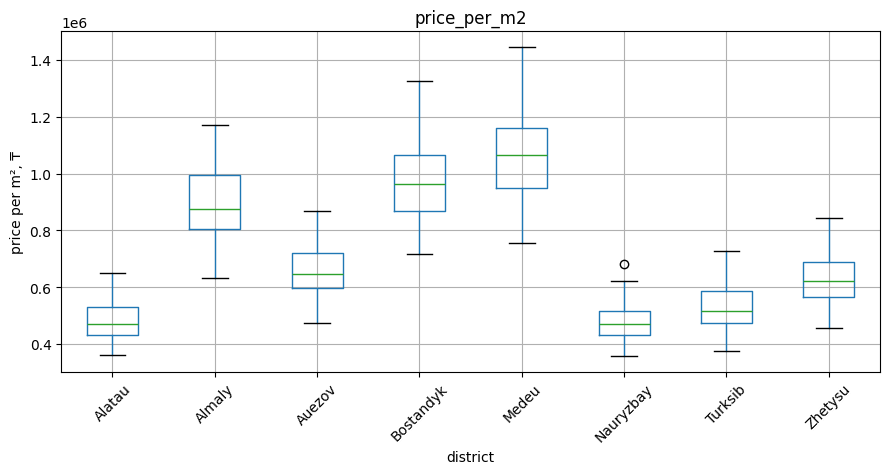

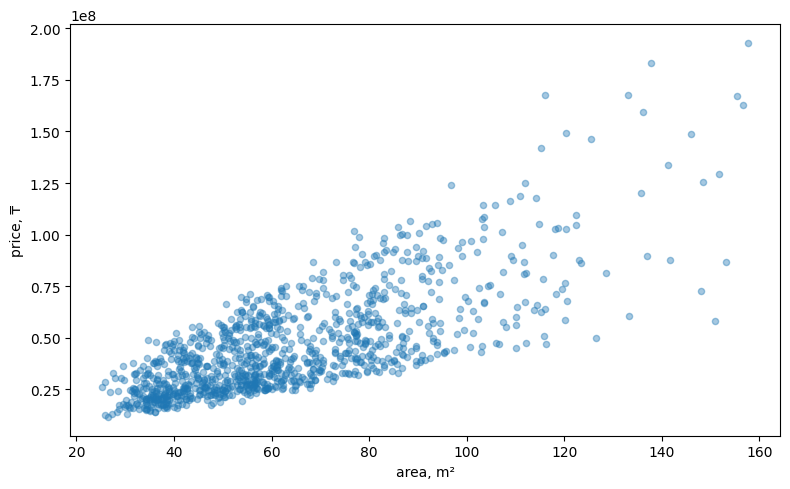

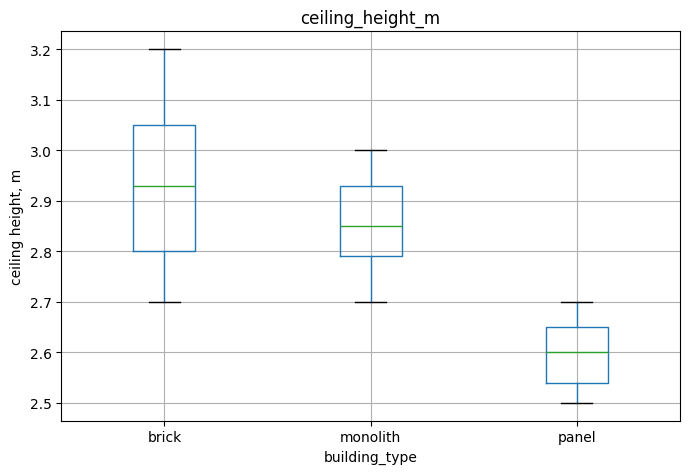

In [40]:
import matplotlib.pyplot as plt


df.boxplot(column="price_per_m2", by="district", rot=45, figsize=(9,5))
plt.ylabel("price per m², ₸")
plt.xlabel("district")
plt.suptitle("")
plt.tight_layout()
plt.show()


df.plot.scatter(x="area_m2", y="price_kzt", alpha=0.4, figsize=(8,5))
plt.xlabel("area, m²")
plt.ylabel("price, ₸")
plt.tight_layout()
plt.show()

df.boxplot(column="ceiling_height_m", by="building_type", figsize=(7,5))
plt.ylabel("ceiling height, m")
plt.suptitle("")
plt.tight_layout()
plt.show()

График 1  Medeu — самый дорогой (медиана ~1.05 млн ₸/м²), Almaly и Bostandyk тоже высоко. Alatau, Nauryzbay, Turksib, Zhetysu — самые дешёвые (~0.5 млн). Разброс между самым дорогим и самым дешёвым районом — примерно 2.3 раза.

График 2  линейная зависимость чёткая. С ростом площади до 100 м² цена растёт предсказуемо, дальше — разброс шире, но явных выбросов нет

График 3 медианы: brick ~2.93 м, monolith ~2.85 м, panel ~2.60 м. В панельках потолки на ~0.3 м ниже, чем в кирпичных

In [41]:
print(df.groupby("district")["price_per_m2"].median().sort_values())
print(df.groupby("building_type")["ceiling_height_m"].median())

district
Alatau       4.685377e+05
Nauryzbay    4.696809e+05
Turksib      5.155426e+05
Zhetysu      6.219716e+05
Auezov       6.476673e+05
Almaly       8.761084e+05
Bostandyk    9.641956e+05
Medeu        1.064710e+06
Name: price_per_m2, dtype: float64
building_type
brick       2.93
monolith    2.85
panel       2.60
Name: ceiling_height_m, dtype: float64


In [42]:
import os
path = "data/almaty_apartments_clean.csv"
print("exists:", os.path.exists(path))
print("size:", os.path.getsize(path), "bytes")
print(df.shape)

exists: True
size: 99750 bytes
(1080, 13)
